# Notebook 1 : le delta hedging sur données simulées

Les prix sont simulés avec le modèle lui-même, donc le modèle est vrai. On teste uniquement la méthode de couverture : la banque vend un call et le couvre avec le delta de Black-Scholes. Est-ce que ça marche ?

Paramètres : $S_0 = 100$, $K = 100$, $T = 1$ an, $r = 3\,\%$, $\sigma = 20\,\%$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spread_options.analytics import bs_call, bs_delta
from spread_options.hedging import delta_hedge_pnl
from spread_options.models import simulate_gbm_paths
from spread_options.products import call_payoff

S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.03, 0.2
price0 = bs_call(S0, K, T, r, sigma)                                # what the client pays us
delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma) # rule Delta(S, tau)
payoff_fn = lambda ST: call_payoff(ST, K)

print(f"price0 = {price0:.2f}")

price0 = 9.41


## 1. Rebalancer plus ou moins souvent

On couvre 1000 chemins simulés en rebalançant 4, 12, 52 ou 252 fois dans l'année, et on regarde le P&L final.

Quatre indicateurs, gardés pour tout le projet : la moyenne (le prix est-il juste ? on attend ≈ 0), l'écart-type (la qualité de la couverture), l'écart-type divisé par la prime, et le pire 5 % (la perte dépassée une fois sur vingt).

In [2]:
results = {} # key = number of rebalancings, value = 1000 P&L
for n_steps in [4, 12, 52, 252]: # quarterly, monthly, weekly, daily
    obs_times = np.linspace(0, T, n_steps + 1)
    paths = simulate_gbm_paths(S0, r, sigma, obs_times, n_paths=1000)
    results[n_steps] = delta_hedge_pnl(paths, T, r, price0, delta_fn, payoff_fn)

In [3]:
for n, pnl in results.items():
    print(f"{n:>4} rebal. | mean {pnl.mean():6.3f} | std {pnl.std():5.2f} "
          f"| std/price {pnl.std() / price0:5.1%} | worst 5% {np.quantile(pnl, 0.05):6.2f}")

   4 rebal. | mean -0.080 | std  3.37 | std/price 35.8% | worst 5%  -5.79
  12 rebal. | mean  0.001 | std  1.92 | std/price 20.4% | worst 5%  -3.38
  52 rebal. | mean  0.057 | std  0.94 | std/price 10.0% | worst 5%  -1.43
 252 rebal. | mean  0.017 | std  0.46 | std/price  4.8% | worst 5%  -0.67


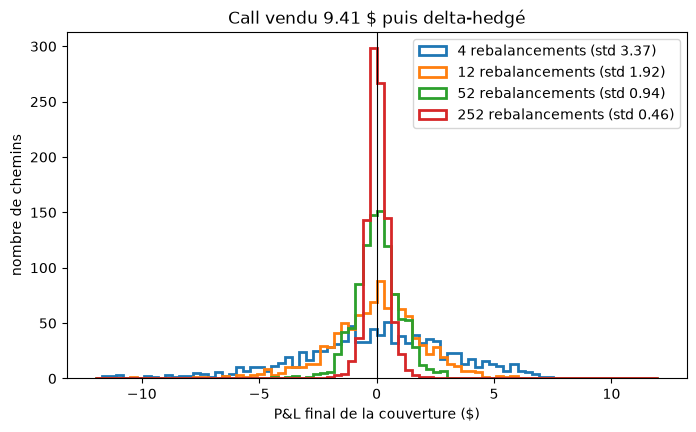

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(-12, 12, 81) # same bins for all curves, so they can be compared
for n, pnl in results.items():
    ax.hist(pnl, bins=bins, histtype="step", linewidth=2, # "step" = outline only, curves stay readable
            label=f"{n} rebalancements (std {pnl.std():.2f})")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("P&L final de la couverture ($)")
ax.set_ylabel("nombre de chemins")
ax.set_title(f"Call vendu {price0:.2f} $ puis delta-hedgé")
ax.legend()
plt.show()

Les quatre cloches sont centrées sur 0 : le prix de 9,41 \$ est juste. Plus on rebalance, plus la cloche est fine. Avec un rebalancement par jour, il reste un écart-type de 4,8 % de la prime, c'est le prix à payer pour ne pas couvrir en continu.

## 2. La loi en $1/\sqrt{n}$

Si l'écart-type vaut $c/\sqrt{n}$, alors écart-type × $\sqrt{n}$ reste constant, et en échelle log les points forment une droite de pente $-1/2$.

In [5]:
n_list = np.array(list(results.keys())) # [4, 12, 52, 252]
stds = np.array([results[n].std() for n in n_list]) # one standard deviation per frequency

for n, s in zip(n_list, stds):
    print(f"{n:>4} rebal. | écart-type {s:.2f} $ | écart-type x racine(n) = {s * np.sqrt(n):.2f}")

# best straight line through the points (ln n, ln std): polyfit returns (slope, intercept)
slope, intercept = np.polyfit(np.log(n_list), np.log(stds), 1)
print(f"pente mesurée en échelle log : {slope:.2f} (théorie : -0.50)")

   4 rebal. | écart-type 3.37 $ | écart-type x racine(n) = 6.73
  12 rebal. | écart-type 1.92 $ | écart-type x racine(n) = 6.66
  52 rebal. | écart-type 0.94 $ | écart-type x racine(n) = 6.78
 252 rebal. | écart-type 0.46 $ | écart-type x racine(n) = 7.23
pente mesurée en échelle log : -0.48 (théorie : -0.50)


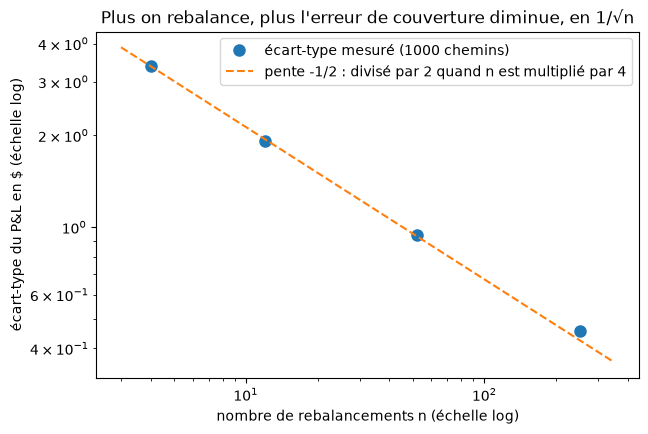

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(n_list, stds, "o", markersize=8, label="écart-type mesuré (1000 chemins)") # both axes in log scale
n_line = np.array([3, 350])
ax.loglog(n_line, stds[0] * (n_line / n_list[0]) ** -0.5, "--", # reference line through the first point
          label="pente -1/2 : divisé par 2 quand n est multiplié par 4")
ax.set_xlabel("nombre de rebalancements n (échelle log)")
ax.set_ylabel("écart-type du P&L en $ (échelle log)")
ax.set_title("Plus on rebalance, plus l'erreur de couverture diminue, en 1/√n")
ax.legend()
plt.show()

Le produit reste proche de 7 et la pente vaut −0,48 : l'erreur de couverture tend bien vers 0 comme $1/\sqrt{n}$. Le gain ralentit vite : passer de 52 à 252 rebalancements ne divise l'erreur que par 2.

## 3. Un chemin, jour par jour

On suit un seul chemin avec un rebalancement par jour. Chaque soir on compare ce que la banque doit (la valeur du call) et son portefeuille de couverture (cash + Δ × S). L'écart entre les deux est le P&L en valeur de marché ; à l'échéance, c'est le P&L final.

In [7]:
from spread_options.hedging import hedge_one_path

n_days = 252
dt = T / n_days
one_path = simulate_gbm_paths(S0, r, sigma, np.linspace(0, T, n_days + 1), n_paths=20)[2] # the 3rd simulated path

cash = price0 # day 0: the client pays the premium
shares = 0.0
owed, portfolio, deltas = [price0], [price0], [] # values on day 0: both equal the premium
for i in range(n_days):
    new_shares = bs_delta(one_path[i], K, T - i * dt, r, sigma) # same steps as hedge_one_path
    cash = cash - (new_shares - shares) * one_path[i] # buy (cash goes down) or sell (cash goes up)
    shares = new_shares
    cash = cash * np.exp(r * dt) # interest until tomorrow
    deltas.append(shares)
    S = one_path[i + 1] # tomorrow's price
    if i + 1 < n_days:
        owed.append(bs_call(S, K, T - (i + 1) * dt, r, sigma)) # what the call is worth tomorrow
    else:
        owed.append(call_payoff(S, K)) # at maturity the call is worth its payoff
    portfolio.append(cash + shares * S) # cash + value of the shares held

owed, portfolio = np.array(owed), np.array(portfolio)
gap = portfolio - owed # market-value P&L, day by day
check = hedge_one_path(one_path, T, r, price0, delta_fn, payoff_fn)
print(f"prix final {one_path[-1]:.1f} $ | payoff {owed[-1]:.2f} $ | portefeuille final {portfolio[-1]:.2f} $")
print(f"P&L final {gap[-1]:+.3f} $ (hedge_one_path : {check:+.3f} $) | plus grand écart dans l'année {np.abs(gap).max():.2f} $")
print(f"le prix a croisé le strike {np.sum(np.diff(np.sign(one_path - K)) != 0)} fois")

prix final 110.8 $ | payoff 10.82 $ | portefeuille final 11.09 $
P&L final +0.274 $ (hedge_one_path : +0.274 $) | plus grand écart dans l'année 0.47 $
le prix a croisé le strike 27 fois


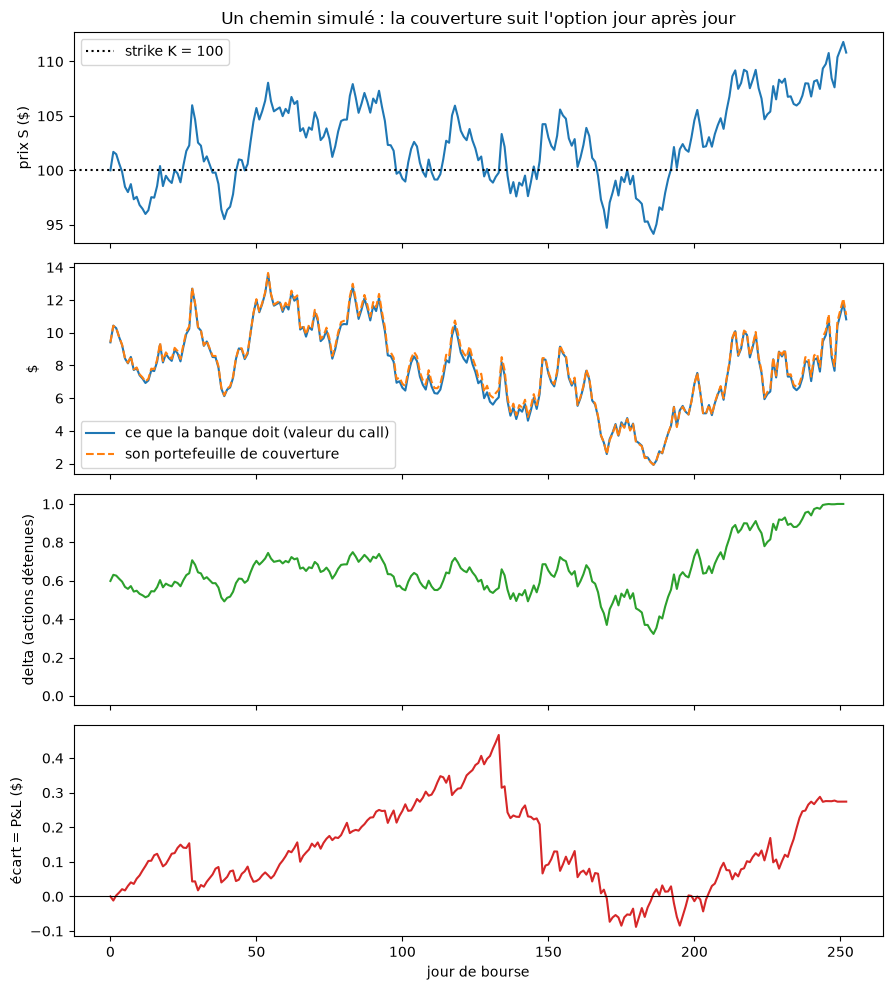

In [8]:
days = np.arange(n_days + 1) # 0, 1, ..., 252
fig, axes = plt.subplots(4, 1, figsize=(9, 10), sharex=True) # 4 panels, same time axis

axes[0].plot(days, one_path, color="tab:blue")
axes[0].axhline(K, color="black", linestyle=":", label="strike K = 100")
axes[0].set_ylabel("prix S ($)")
axes[0].legend()

axes[1].plot(days, owed, label="ce que la banque doit (valeur du call)")
axes[1].plot(days, portfolio, "--", label="son portefeuille de couverture")
axes[1].set_ylabel("$")
axes[1].legend()

axes[2].plot(days[:-1], deltas, color="tab:green") # delta is chosen on days 0 to 251
axes[2].set_ylabel("delta (actions détenues)")
axes[2].set_ylim(-0.05, 1.05)

axes[3].plot(days, gap, color="tab:red")
axes[3].axhline(0, color="black", linewidth=0.8)
axes[3].set_ylabel("écart = P&L ($)")
axes[3].set_xlabel("jour de bourse")

axes[0].set_title("Un chemin simulé : la couverture suit l'option jour après jour")
plt.tight_layout() # avoid overlapping labels
plt.show()

Le portefeuille colle au call toute l'année et l'écart ne dépasse jamais 0,47 \$. Le P&L final (+0,27 \$) est celui de `hedge_one_path`. L'écart monte un peu les jours calmes et descend d'un coup les jours de gros mouvement près du strike (jours 27, 133, 147).

## 4. Pourquoi l'écart bouge : les jours 111 et 133

Le portefeuille est une droite de pente Δ, le call est une courbe. Chaque jour :

- le mouvement du prix coûte environ $\tfrac12\Gamma(\Delta S)^2$ (la courbe passe au-dessus de la droite) ;
- le temps rapporte une rente (le call perd un peu de valeur, thêta), moins les intérêts.

Les deux s'équilibrent pour un mouvement « normal », $\sigma/\sqrt{252} = 1{,}26\,\%$ par jour à 20 %. Un mouvement $k$ fois plus grand coûte environ $k^2$ fois la rente.

In [9]:
dt = T / n_days
normal = sigma * np.sqrt(dt) # normal daily move predicted by sigma: 1.26%
for day in [111, 133]: # a calm day, then a big move near the strike
    S, S_next = one_path[day], one_path[day + 1]
    tau = T - day * dt # time left on that evening
    d = deltas[day] # shares held from this evening to tomorrow
    gamma = (bs_delta(S + 0.01, K, tau, r, sigma) - bs_delta(S - 0.01, K, tau, r, sigma)) / 0.02
    call_same_time = bs_call(S_next, K, tau, r, sigma) # tomorrow's price, but no time has passed
    price_effect = call_same_time - owed[day] # what the call gains because the price moved
    time_gain = call_same_time - owed[day + 1] # what the call loses because one day passed (thêta)
    shares_gain = d * (S_next - S)
    cash = portfolio[day] - d * S # cash after the evening trade (negative: borrowed)
    interest = cash * (np.exp(r * dt) - 1) # one day of interest (negative: paid)
    move_cost = price_effect - shares_gain # the curve goes above the straight line
    rent = time_gain + interest # net daily rent: time decay minus interest
    k = abs(S_next / S - 1) / normal # how many "normal moves" the price made
    breakeven = np.sqrt(2 * rent / gamma) # move whose cost 1/2 gamma dS^2 equals the rent
    print(f"jour {day} | S {S:.2f} -> {S_next:.2f} ({S_next / S - 1:+.2%}, k = {k:.2f} mouvements normaux) "
          f"| delta {d:.3f} | gamma {gamma:.4f}")
    print(f"   actions {shares_gain:+.3f} $ | le call bouge de {price_effect:+.3f} $ (prix) et {-time_gain:+.3f} $ (temps)")
    print(f"   coût du mouvement {move_cost:.3f} $ (formule 1/2 gamma dS^2 : {0.5 * gamma * (S_next - S)**2:.3f} $) "
          f"| gain du temps {time_gain:.3f} $ | intérêts {interest:+.3f} $")
    print(f"   P&L du jour = {time_gain:.3f} {interest:+.3f} - {move_cost:.3f} = {rent - move_cost:+.3f} $ "
          f"(écart de la figure : {gap[day + 1] - gap[day]:+.3f} $)")
    print(f"   rente nette {rent:.3f} $ -> mouvement d'équilibre {breakeven:.2f} $ ({breakeven / S:.2%}) ; "
          f"règle k² : coût ≈ {k**2:.2f} x {rent:.3f} = {k**2 * rent:.3f} $")
    print()

jour 111 | S 99.16 -> 99.15 (-0.01%, k = 0.01 mouvements normaux) | delta 0.552 | gamma 0.0267
   actions -0.004 $ | le call bouge de -0.004 $ (prix) et -0.027 $ (temps)
   coût du mouvement 0.000 $ (formule 1/2 gamma dS^2 : 0.000 $) | gain du temps 0.027 $ | intérêts -0.006 $
   P&L du jour = 0.027 -0.006 - 0.000 = +0.021 $ (écart de la figure : +0.021 $)
   rente nette 0.021 $ -> mouvement d'équilibre 1.25 $ (1.26%) ; règle k² : coût ≈ 0.00 x 0.021 = 0.000 $

jour 133 | S 99.79 -> 103.34 (+3.56%, k = 2.83 mouvements normaux) | delta 0.562 | gamma 0.0287
   actions +1.996 $ | le call bouge de +2.172 $ (prix) et -0.029 $ (temps)
   coût du mouvement 0.176 $ (formule 1/2 gamma dS^2 : 0.181 $) | gain du temps 0.029 $ | intérêts -0.006 $
   P&L du jour = 0.029 -0.006 - 0.176 = -0.153 $ (écart de la figure : -0.153 $)
   rente nette 0.023 $ -> mouvement d'équilibre 1.27 $ (1.27%) ; règle k² : coût ≈ 7.98 x 0.023 = 0.185 $



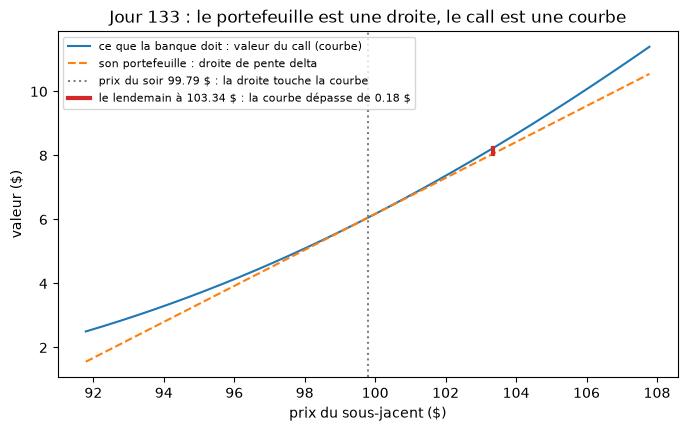

In [10]:
day = 133
S, S_next = one_path[day], one_path[day + 1]
tau = T - day * dt
grid = np.linspace(S - 8, S + 8, 200) # prices around the evening price
curve = bs_call(grid, K, tau, r, sigma) # call value if the price were x (same evening, no time passing)
line = owed[day] + deltas[day] * (grid - S) # hedge: value changes by delta per $ of price

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid, curve, label="ce que la banque doit : valeur du call (courbe)")
ax.plot(grid, line, "--", label="son portefeuille : droite de pente delta")
ax.axvline(S, color="gray", linestyle=":", label=rf"prix du soir {S:.2f} \$ : la droite touche la courbe")
gap_top = bs_call(S_next, K, tau, r, sigma)
gap_bottom = owed[day] + deltas[day] * (S_next - S)
ax.plot([S_next, S_next], [gap_bottom, gap_top], color="tab:red", linewidth=3,
        label=rf"le lendemain à {S_next:.2f} \$ : la courbe dépasse de {gap_top - gap_bottom:.2f} \$")
ax.set_xlabel("prix du sous-jacent ($)")
ax.set_ylabel("valeur ($)")
ax.set_title(f"Jour {day} : le portefeuille est une droite, le call est une courbe")
ax.legend(fontsize=8)
plt.show()

Jour 111 : le prix ne bouge pas, la banque gagne la rente (+0,021 \$). Jour 133 : le prix bondit de 3,56 %, soit 2,8 mouvements normaux, près du strike. Le mouvement coûte 0,176 \$, environ $2{,}8^2 \approx 8$ fois la rente de 0,023 \$, d'où −0,15 \$. Sur l'année, si σ est le bon, les jours calmes et les jours agités se compensent presque.

## 5. Et si la vol du modèle est fausse ?

La banque price et couvre à 20 %, mais le marché simulé bouge à 10, 15, 20, 25 ou 30 %. On compare deux couvertures avec la même prime (celle à 20 %) : A avec le delta à 20 %, B avec le delta à la vraie vol. Environ une minute de calcul.

In [11]:
vols_real = [0.10, 0.15, 0.20, 0.25, 0.30] # true volatility of the simulated market
obs_times = np.linspace(0, T, 253) # daily rebalancing
pnl_A, pnl_B, theory = {}, {}, {}
for s_real in vols_real:
    paths = simulate_gbm_paths(S0, r, s_real, obs_times, n_paths=500) # the market moves at s_real
    # A: delta with the model vol (20%), as the bank does
    pnl_A[s_real] = delta_hedge_pnl(paths, T, r, price0, delta_fn, payoff_fn)
    # B: same premium, but delta with the true vol
    delta_true = lambda S, time_left: bs_delta(S, K, time_left, r, s_real)
    pnl_B[s_real] = delta_hedge_pnl(paths, T, r, price0, delta_true, payoff_fn)
    theory[s_real] = price0 - bs_call(S0, K, T, r, s_real) # premium received - "fair" premium
    print(f"vol réalisée {s_real:4.0%} | attendu {theory[s_real]:+.2f} $ "
          f"| A (delta 20 %) : moyenne {pnl_A[s_real].mean():+.2f}, écart-type {pnl_A[s_real].std():.2f}, "
          f"pire 5 % {np.quantile(pnl_A[s_real], 0.05):+.2f} "
          f"| B (delta vraie vol) : moyenne {pnl_B[s_real].mean():+.2f}, écart-type {pnl_B[s_real].std():.2f}")

vol réalisée  10% | attendu +3.83 $ | A (delta 20 %) : moyenne +4.01, écart-type 1.02, pire 5 % +2.30 | B (delta vraie vol) : moyenne +3.95, écart-type 0.22


vol réalisée  15% | attendu +1.93 $ | A (delta 20 %) : moyenne +2.03, écart-type 0.75, pire 5 % +0.90 | B (delta vraie vol) : moyenne +2.01, écart-type 0.34


vol réalisée  20% | attendu +0.00 $ | A (delta 20 %) : moyenne +0.03, écart-type 0.47, pire 5 % -0.68 | B (delta vraie vol) : moyenne +0.03, écart-type 0.47


vol réalisée  25% | attendu -1.94 $ | A (delta 20 %) : moyenne -1.99, écart-type 0.98, pire 5 % -3.78 | B (delta vraie vol) : moyenne -1.97, écart-type 0.59


vol réalisée  30% | attendu -3.87 $ | A (delta 20 %) : moyenne -4.02, écart-type 1.90, pire 5 % -7.44 | B (delta vraie vol) : moyenne -3.96, écart-type 0.70


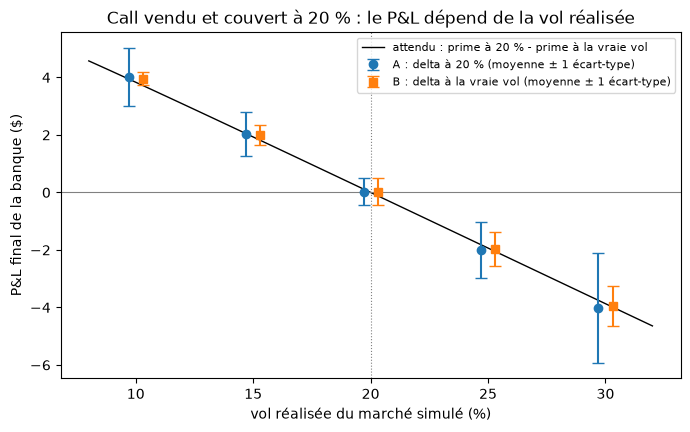

In [12]:
x = np.array(vols_real) * 100 # in %
grid = np.linspace(0.08, 0.32, 100)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid * 100, [price0 - bs_call(S0, K, T, r, s) for s in grid], color="black", linewidth=1,
        label="attendu : prime à 20 % - prime à la vraie vol")
ax.errorbar(x - 0.3, [pnl_A[s].mean() for s in vols_real], yerr=[pnl_A[s].std() for s in vols_real],
            fmt="o", capsize=4, label="A : delta à 20 % (moyenne ± 1 écart-type)") # shifted left
ax.errorbar(x + 0.3, [pnl_B[s].mean() for s in vols_real], yerr=[pnl_B[s].std() for s in vols_real],
            fmt="s", capsize=4, label="B : delta à la vraie vol (moyenne ± 1 écart-type)") # shifted right
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(20, color="gray", linestyle=":", linewidth=0.8) # the model vol
ax.set_xlabel("vol réalisée du marché simulé (%)")
ax.set_ylabel("P&L final de la banque ($)")
ax.set_title("Call vendu et couvert à 20 % : le P&L dépend de la vol réalisée")
ax.legend(fontsize=8)
plt.show()

Le P&L moyen suit la courbe attendue, prime à 20 % moins prime à la vraie vol : environ 0,39 \$ par point de vol. Le bon delta (B) ne change pas la moyenne, il réduit la dispersion (écart-type 0,70 \$ contre 1,90 \$ à 30 %). À 30 %, le pire 5 % vaut −7,44 \$ pour une prime de 9,41 \$.

## Ce qu'on retient

- Quand le modèle est vrai, la couverture marche : P&L moyen ≈ 0, écart-type qui baisse en $1/\sqrt{n}$ (4,8 % de la prime en quotidien).
- Chaque jour, la banque gagne la rente du temps et paie le mouvement au carré ; l'équilibre est le mouvement normal prévu par σ.
- Si σ est faux, la banque perd ou gagne l'erreur de prime (≈ 0,39 \$ par point de vol). C'est l'estimation de σ (notebook 2) qui décide du résultat.